In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
project_path = Path.cwd()

dataset_path = project_path / "dataset" / "SDNET2018"

print("Project folder:", project_path)
print("Dataset folder:", dataset_path)
print("Dataset exists:", dataset_path.exists())

Project folder: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan
Dataset folder: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\dataset\SDNET2018
Dataset exists: True


In [3]:
for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        print(folder.name)

D
P
W


In [4]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

category_paths = {
    "CD": dataset_path / "D" / "CD",
    "UD": dataset_path / "D" / "UD",
    "CP": dataset_path / "P" / "CP",
    "UP": dataset_path / "P" / "UP",
    "CW": dataset_path / "W" / "CW",
    "UW": dataset_path / "W" / "UW",
}

category_counts = {}

for category, folder in category_paths.items():
    if folder.exists():
        count = sum(
            1 for path in folder.rglob("*")
            if path.is_file()
            and path.suffix.lower() in image_extensions
        )
        category_counts[category] = count
    else:
        print("Folder not found:", folder)

counts_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

display(counts_df)
print("Total images:", counts_df["Image Count"].sum())

,Category,Image Count
0,CD,2025
1,UD,11595
2,CP,2608
3,UP,21726
4,CW,3851
5,UW,14287


Total images: 56092


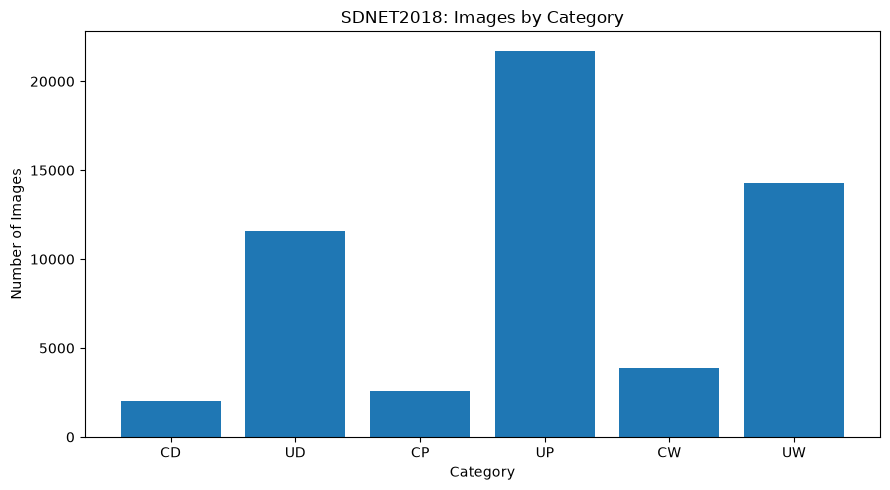

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    counts_df["Category"],
    counts_df["Image Count"]
)

plt.title("SDNET2018: Images by Category")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

In [6]:
cracked_categories = ["CD", "CP", "CW"]
uncracked_categories = ["UD", "UP", "UW"]

cracked_count = sum(
    category_counts.get(c, 0)
    for c in cracked_categories
)

uncracked_count = sum(
    category_counts.get(c, 0)
    for c in uncracked_categories
)

class_df = pd.DataFrame({
    "Class": ["Cracked", "Uncracked"],
    "Image Count": [cracked_count, uncracked_count]
})

class_df["Percentage"] = (
    class_df["Image Count"]
    / class_df["Image Count"].sum()
    * 100
)

display(class_df.round(2))


,Class,Image Count,Percentage
0,Cracked,8484,15.13
1,Uncracked,47608,84.87


In [7]:

# Check the dimensions of images in SDNET2018

for category, folder in category_paths.items():
    if not folder.exists():
        print(category, "- Folder not found")
        continue

    images = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

    print(f"\nCategory: {category}")

    for path in images[:3]:
        try:
            with Image.open(path) as img:
                print(path.name, "->", img.size)
        except Exception as e:
            print("Could not read:", path.name, e)



Category: CD
7001-115.jpg -> (256, 256)
7001-139.jpg -> (256, 256)
7001-151.jpg -> (256, 256)

Category: UD
7001-1.jpg -> (256, 256)
7001-10.jpg -> (256, 256)
7001-100.jpg -> (256, 256)

Category: CP
001-100.jpg -> (256, 256)
001-101.jpg -> (256, 256)
001-102.jpg -> (256, 256)

Category: UP
001-1.jpg -> (256, 256)
001-10.jpg -> (256, 256)
001-108.jpg -> (256, 256)

Category: CW
7069-101.jpg -> (256, 256)
7069-104.jpg -> (256, 256)
7069-105.jpg -> (256, 256)

Category: UW
7069-1.jpg -> (256, 256)
7069-10.jpg -> (256, 256)
7069-100.jpg -> (256, 256)


In [8]:

image_details = []

for category, folder in category_paths.items():
    if not folder.exists():
        continue

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in image_extensions:
            image_details.append({
                "Category": category,
                "Filename": path.name,
                "File Size (KB)": round(
                    path.stat().st_size / 1024, 2
                )
            })

image_df = pd.DataFrame(image_details)

print("Total image files:", len(image_df))
display(image_df.head())

print("\nFile size statistics:")
display(image_df["File Size (KB)"].describe().round(2))


Total image files: 56092


,Category,Filename,File Size (KB)
0,CD,7001-115.jpg,9.53
1,CD,7001-139.jpg,7.20
2,CD,7001-151.jpg,8.13
3,CD,7001-157.jpg,7.24
4,CD,7001-169.jpg,7.42



File size statistics:


count    56092.00
mean         9.24
std          3.82
min          1.78
25%          6.20
50%          8.08
75%         12.18
max         21.91
Name: File Size (KB), dtype: float64

In [9]:
import random

SAMPLE_PER_CATEGORY = 100
rng = random.Random(42)
image_details = []
read_errors = []

for category, folder in category_paths.items():
    if not folder.exists():
        print(f"{category}: folder not found ({folder})")
        continue

    images = [
        path for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]
    sample = rng.sample(images, min(SAMPLE_PER_CATEGORY, len(images)))

    for path in sample:
        try:
            with Image.open(path) as img:
                width, height = img.size

            image_details.append({
                "Category": category,
                "Filename": path.name,
                "Width": width,
                "Height": height,
                "File Size (KB)": round(path.stat().st_size / 1024, 2),
            })
        except OSError as exc:
            read_errors.append((path, exc))

image_df = pd.DataFrame(image_details)
print(f"Readable sampled images: {len(image_df)} (up to {SAMPLE_PER_CATEGORY} per category)")
print("Images that could not be read:", len(read_errors))

if not image_df.empty:
    print(
        "Different image dimensions in sample:",
        image_df[["Width", "Height"]].drop_duplicates().shape[0],
    )
    display(image_df[["Width", "Height", "File Size (KB)"]].describe().round(2))

if read_errors:
    print("First unreadable image:", read_errors[0][0], "-", read_errors[0][1])

Readable sampled images: 600 (up to 100 per category)
Images that could not be read: 0
Different image dimensions in sample: 1


,Width,Height,File Size (KB)
count,600.0,600.0,600.00
mean,256.0,256.0,8.87
std,0.0,0.0,3.55
min,256.0,256.0,2.20
25%,256.0,256.0,6.19
50%,256.0,256.0,7.78
75%,256.0,256.0,10.96
max,256.0,256.0,20.35


In [10]:

for category, folder in category_paths.items():
    if not folder.exists():
        print(category, "- Folder not found")
        continue

    images = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

    if images:
        try:
            with Image.open(images[0]) as img:
                print(
                    category,
                    "| Image:", images[0].name,
                    "| Dimensions:", img.size
                )
        except Exception as e:
            print(category, "| Could not read image:", e)


CD | Image: 7001-115.jpg | Dimensions: (256, 256)
UD | Image: 7001-1.jpg | Dimensions: (256, 256)
CP | Image: 001-100.jpg | Dimensions: (256, 256)
UP | Image: 001-1.jpg | Dimensions: (256, 256)
CW | Image: 7069-101.jpg | Dimensions: (256, 256)
UW | Image: 7069-1.jpg | Dimensions: (256, 256)


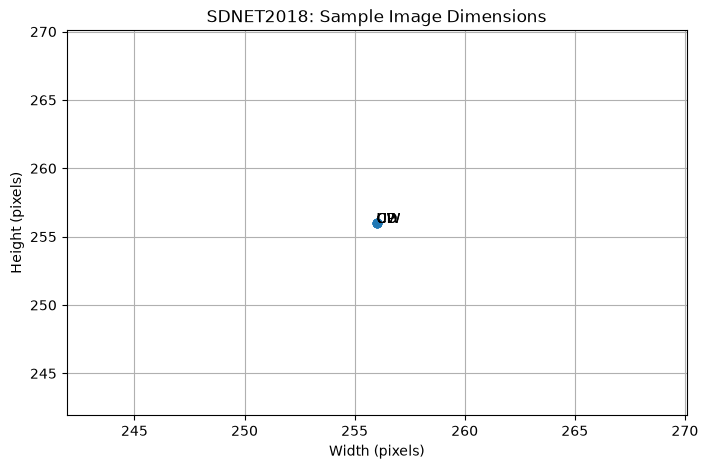

In [11]:

categories = ["CD", "UD", "CP", "UP", "CW", "UW"]
widths = [256, 256, 256, 256, 256, 256]
heights = [256, 256, 256, 256, 256, 256]

plt.figure(figsize=(8, 5))

plt.scatter(widths, heights)

for i, category in enumerate(categories):
    plt.annotate(category, (widths[i], heights[i]))

plt.title("SDNET2018: Sample Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(True)
plt.show()


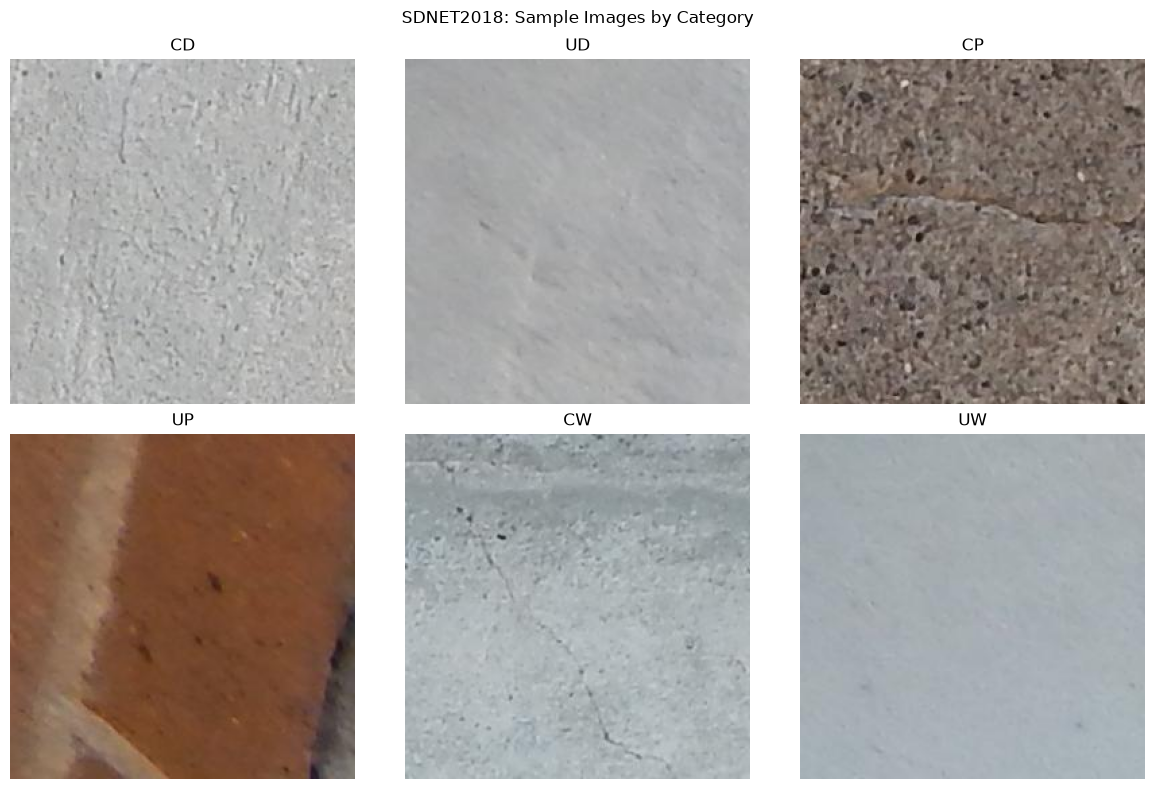

In [12]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (category, folder) in zip(axes.flat, category_paths.items()):
    ax.axis("off")

    if folder.exists():
        images = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in image_extensions
        ]

        if images:
            try:
                with Image.open(images[0]) as img:
                    ax.imshow(img.convert("RGB"))

                ax.set_title(category)
            except Exception:
                ax.set_title(f"{category} - Cannot read")
        else:
            ax.set_title(f"{category} - No images")

plt.suptitle("SDNET2018: Sample Images by Category")
plt.tight_layout()
plt.show()


In [13]:

corrupted_images = []
checked_images = 0
sample_limit = 100

for category, folder in category_paths.items():
    if not folder.exists():
        continue

    images = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

    for path in images:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(str(path))

        checked_images += 1

        if checked_images >= sample_limit:
            break

    if checked_images >= sample_limit:
        break

print("Images checked:", checked_images)
print("Unreadable images found:", len(corrupted_images))

if corrupted_images:
    print("Sample unreadable paths:")
    for path in corrupted_images[:10]:
        print(path)


Images checked: 100
Unreadable images found: 0


In [14]:
from pathlib import Path

output_path = project_path / "outputs" / "eda"
output_path.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_path)
print("Folder exists:", output_path.exists())

Output folder: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\outputs\eda
Folder exists: True


In [15]:
counts_df.to_csv(
    output_path / "sdnet_category_counts.csv",
    index=False
)

print("Category counts saved successfully!")
print(counts_df)

Category counts saved successfully!
  Category  Image Count
0       CD         2025
1       UD        11595
2       CP         2608
3       UP        21726
4       CW         3851
5       UW        14287


In [16]:
class_df.to_csv(
    output_path / "sdnet_class_distribution.csv",
    index=False
)

print("Class distribution saved successfully!")
print(class_df)

Class distribution saved successfully!
       Class  Image Count  Percentage
0    Cracked         8484   15.125152
1  Uncracked        47608   84.874848


In [17]:
image_details = []

for category, folder in category_paths.items():
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in image_extensions:
            image_details.append({
                "Category": category,
                "Filename": path.name,
                "File Size (KB)": round(path.stat().st_size / 1024, 2)
            })

image_df = pd.DataFrame(image_details)

print("Total image records:", len(image_df))
print(image_df.head())

Total image records: 56092
  Category      Filename  File Size (KB)
0       CD  7001-115.jpg            9.53
1       CD  7001-139.jpg            7.20
2       CD  7001-151.jpg            8.13
3       CD  7001-157.jpg            7.24
4       CD  7001-169.jpg            7.42


In [18]:
image_df.to_csv(
    output_path / "sdnet_image_details.csv",
    index=False
)

print("File saved successfully!")
print("Total records:", len(image_df))
print("File path:", output_path / "sdnet_image_details.csv")

File saved successfully!
Total records: 56092
File path: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\outputs\eda\sdnet_image_details.csv


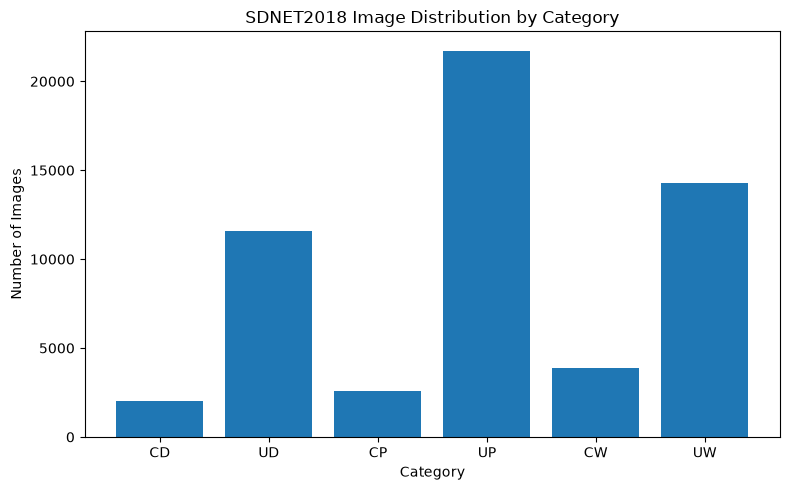

Category distribution chart saved!


In [19]:
plt.figure(figsize=(8, 5))

plt.bar(counts_df.iloc[:, 0], counts_df.iloc[:, 1])
plt.title("SDNET2018 Image Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    output_path / "sdnet_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Category distribution chart saved!")

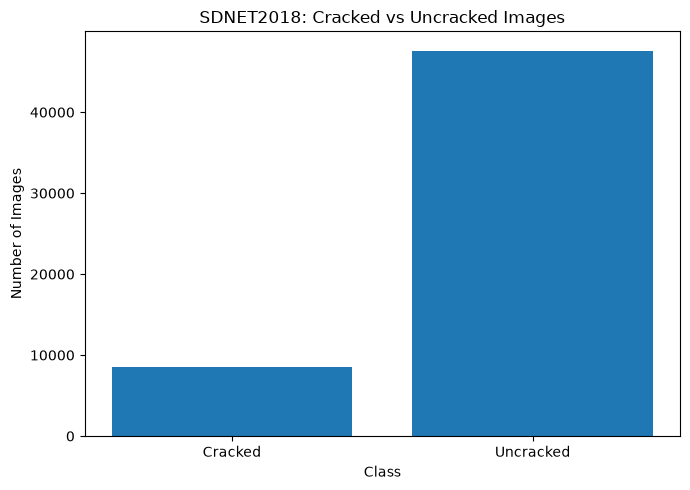

Class distribution chart saved!


In [20]:
plt.figure(figsize=(7, 5))

plt.bar(
    class_df.iloc[:, 0],
    class_df.iloc[:, 1]
)

plt.title("SDNET2018: Cracked vs Uncracked Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    output_path / "sdnet_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart saved!")

In [21]:
summary = f"""
SDNET2018 EXPLORATORY DATA ANALYSIS
==================================

1. Total Images: {len(image_df)}

2. Category Distribution:
{counts_df.to_string(index=False)}

3. Cracked vs Uncracked Distribution:
{class_df.to_string(index=False)}

4. Image File Size Statistics:
{image_df["File Size (KB)"].describe().to_string()}

5. Image Dimensions:
One sample image from each of the six categories
was checked. All sampled images were 256 x 256 pixels.

6. Image Readability:
100 images were checked for readability.
Unreadable images found in this sample: 0.

Note: Dimension and readability checks were sample-based,
not full-dataset validation.
"""

summary_path = output_path / "sdnet_eda_summary.txt"
summary_path.write_text(summary, encoding="utf-8")

print("EDA summary saved successfully!")
print("Saved to:", summary_path)
print(summary)

EDA summary saved successfully!
Saved to: c:\Users\Rakshitha L\OneDrive\Desktop\InfraScan\outputs\eda\sdnet_eda_summary.txt

SDNET2018 EXPLORATORY DATA ANALYSIS

1. Total Images: 56092

2. Category Distribution:
Category  Image Count
      CD         2025
      UD        11595
      CP         2608
      UP        21726
      CW         3851
      UW        14287

3. Cracked vs Uncracked Distribution:
    Class  Image Count  Percentage
  Cracked         8484   15.125152
Uncracked        47608   84.874848

4. Image File Size Statistics:
count    56092.000000
mean         9.240764
std          3.818049
min          1.780000
25%          6.200000
50%          8.080000
75%         12.180000
max         21.910000

5. Image Dimensions:
One sample image from each of the six categories
was checked. All sampled images were 256 x 256 pixels.

6. Image Readability:
100 images were checked for readability.
Unreadable images found in this sample: 0.

Note: Dimension and readability checks were samp